## Methodologies Notebook

1) Nx Graph Creation 
2) Transformation from Cyclic Graphs to Tiered DAGs

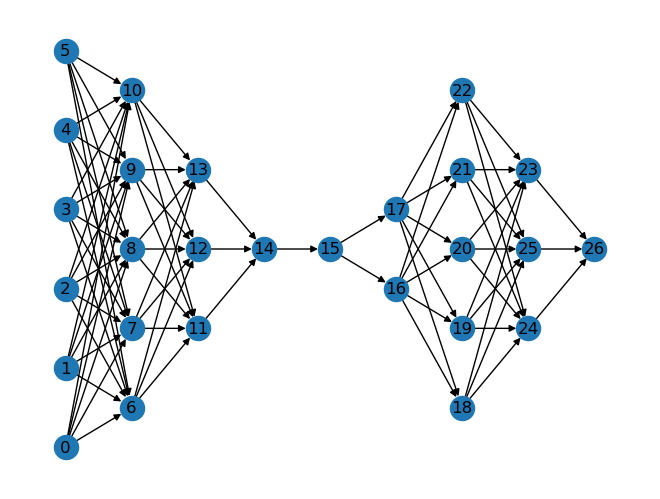

In [1]:
from src.graph_utils import create_layered_graph
import networkx as nx

layer_sizes = [6, 5, 3, 1, 1, 2, 5, 3, 1]
G, layers = create_layered_graph(layer_sizes)
pos = nx.multipartite_layout(G, subset_key='layer', align='vertical', scale=2)
nx.draw(G, pos, with_labels=True)

node: 0, power: ['high', 'medium'], roles: ['A']
node: 1, power: ['high', 'low'], roles: ['A']
node: 2, power: ['medium', 'high'], roles: ['A']
node: 3, power: ['low', 'medium'], roles: ['A']
node: 4, power: ['medium', 'high'], roles: ['A']
node: 5, power: ['medium', 'high'], roles: ['A']
node: 6, power: ['medium', 'high'], roles: ['A', 'B']
node: 7, power: ['medium', 'high'], roles: ['A', 'B']
node: 8, power: ['medium', 'high'], roles: ['A', 'B']
node: 9, power: ['medium', 'low'], roles: ['A', 'B']
node: 10, power: ['high', 'medium'], roles: ['A', 'B']
node: 11, power: ['medium', 'high'], roles: ['A', 'B', 'C']
node: 12, power: ['low', 'high'], roles: ['A', 'B', 'C']
node: 13, power: ['medium', 'high'], roles: ['A', 'B', 'C']
node: 16, power: ['medium', 'low'], roles: ['B', 'C']
node: 17, power: ['low', 'medium'], roles: ['B', 'C']
node: 18, power: ['medium', 'low'], roles: ['B', 'C']
node: 19, power: ['medium', 'high'], roles: ['B', 'C']
node: 20, power: ['low', 'high'], roles: ['B',

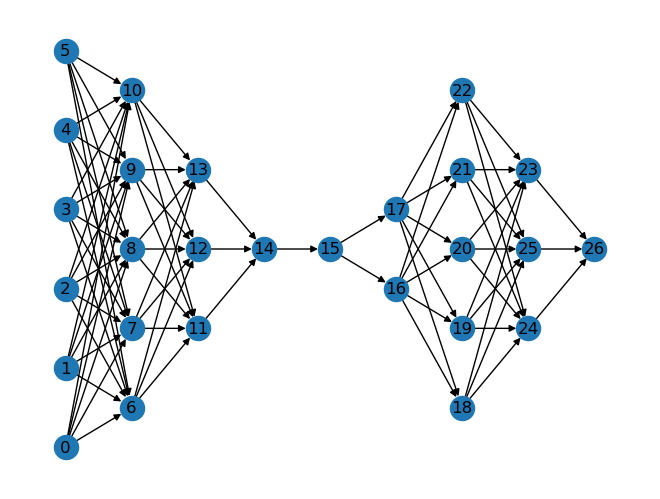

In [2]:
import numpy as np
from src.graph_utils import assign_properties

layer_role_assign = {0: ['A'], 1: ['A', 'B'], 2: ['A', 'B', 'C'], 3: ['A', 'B', 'C'], 4: ['A', 'B', 'C'], 5: ['B', 'C'], 6: ['B', 'C'], 7: ['C'], 8: ['C']}
G = assign_properties(G, layer_sizes, layer_role_assign=layer_role_assign)
nx.draw(G, pos, with_labels=True, node_size=300)


In [3]:
G.nodes(data=True)

NodeDataView({0: {'layer': 0, 'demand': -2, 'probability1': 0.6868577229941826, 'probability2': 0.7844808207397531, 'cost': 4, 'power': ['high', 'medium'], 'role': ['A']}, 1: {'layer': 0, 'demand': -3, 'probability1': 0.6933171606305761, 'probability2': 0.9938525672183042, 'cost': 9, 'power': ['high', 'low'], 'role': ['A']}, 2: {'layer': 0, 'demand': -2, 'probability1': 0.9058118906745976, 'probability2': 0.7641168925565982, 'cost': 6, 'power': ['medium', 'high'], 'role': ['A']}, 3: {'layer': 0, 'demand': -1, 'probability1': 0.8347843380832469, 'probability2': 0.8552255110721634, 'cost': 8, 'power': ['low', 'medium'], 'role': ['A']}, 4: {'layer': 0, 'demand': -2, 'probability1': 0.8238338467862462, 'probability2': 0.6487585130776284, 'cost': 6, 'power': ['medium', 'high'], 'role': ['A']}, 5: {'layer': 0, 'demand': -2, 'probability1': 0.9216579363739279, 'probability2': 0.9804548344787861, 'cost': 3, 'power': ['medium', 'high'], 'role': ['A']}, 6: {'layer': 1, 'demand': 0, 'probability1

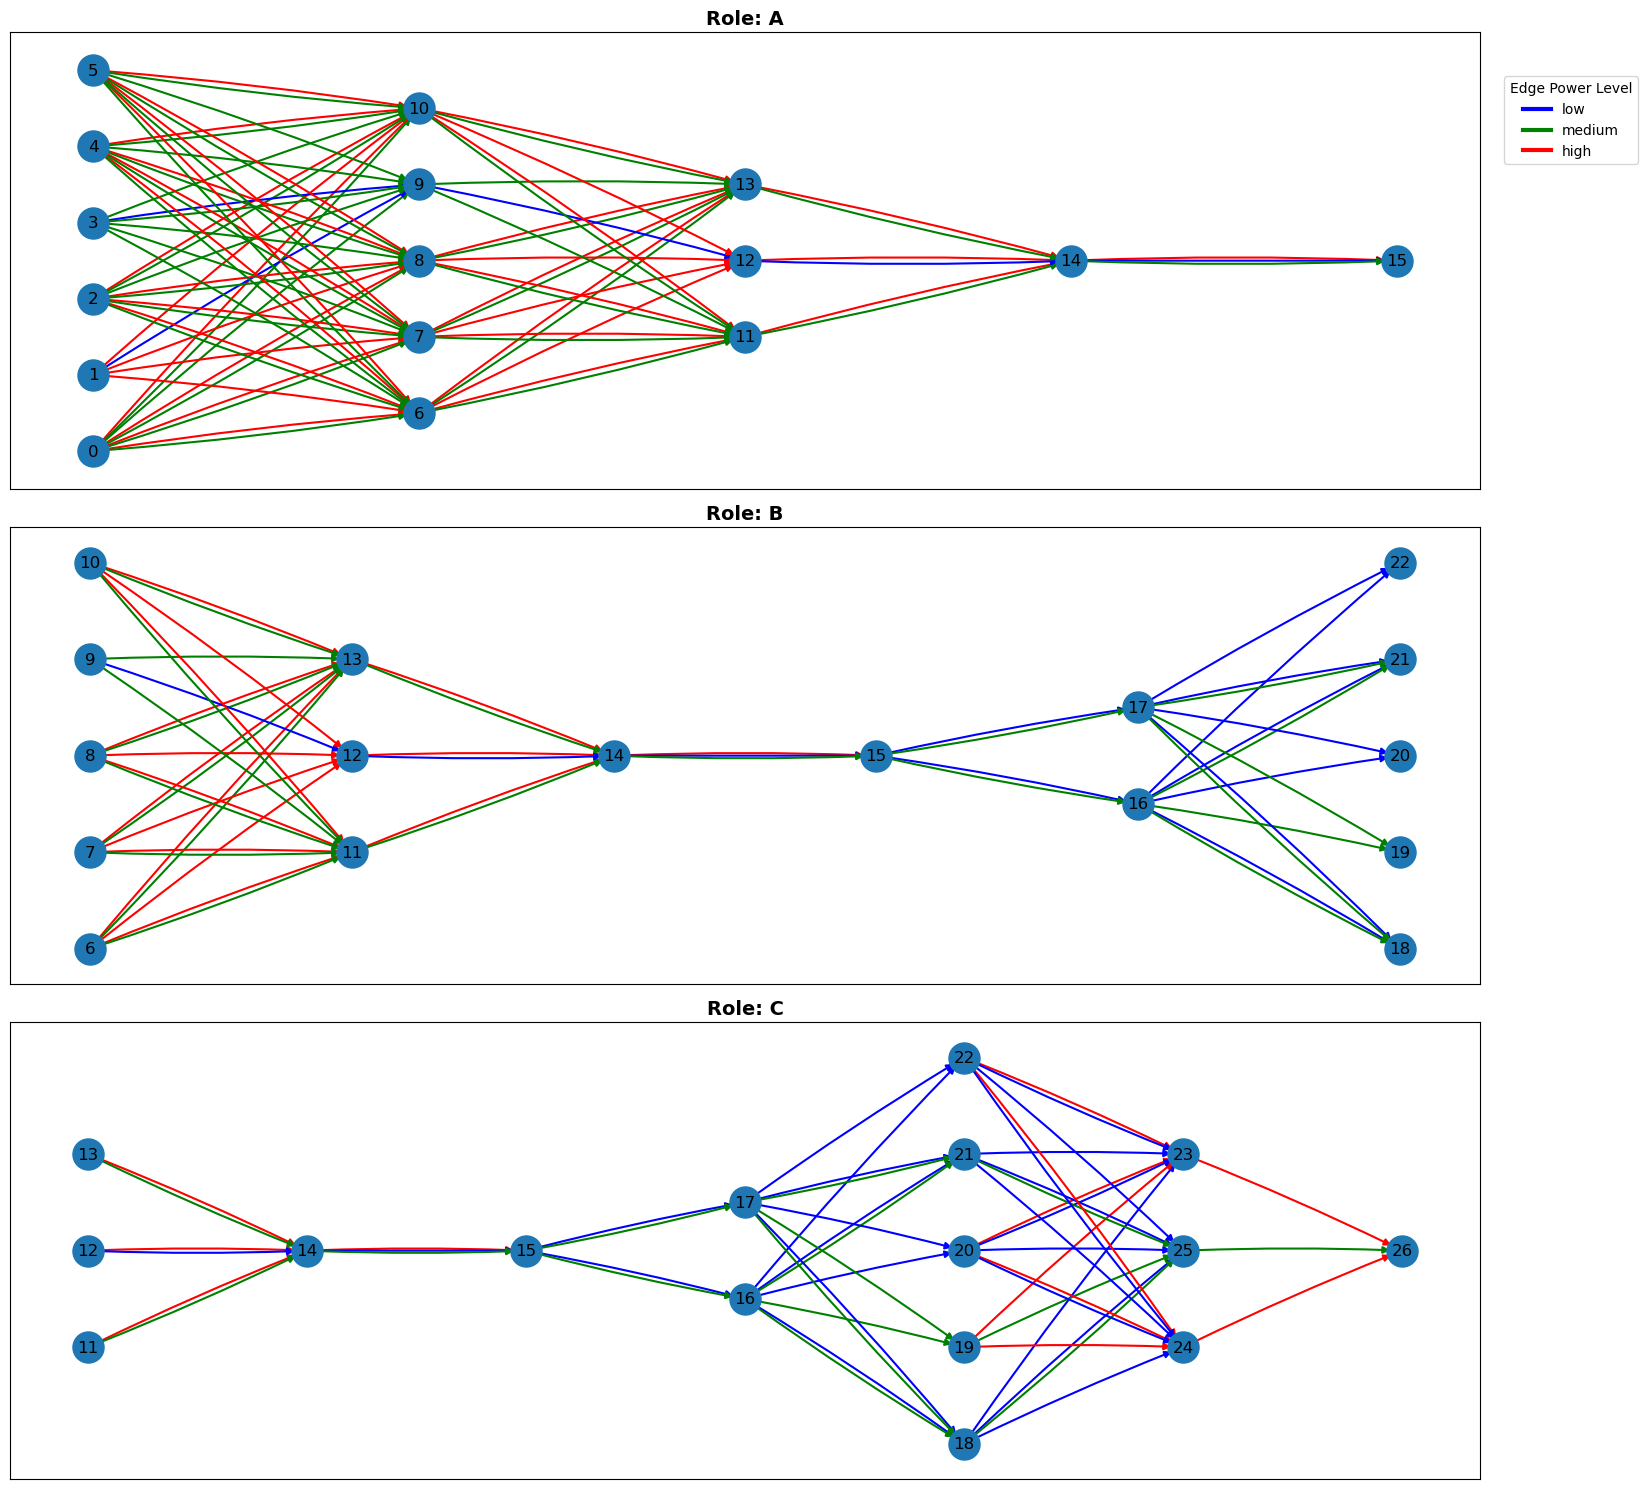

In [4]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def draw_power_edges(subgraph, pos, ax):

    POWER_COLORS = {"low": "blue","medium": "green","high": "red"}
    legend_used = set()
    for u, v, _ in subgraph.edges(data=True):
        u_power = set(subgraph.nodes[u].get("power", []))
        v_power = set(subgraph.nodes[v].get("power", []))
        shared = sorted(u_power & v_power)
        if not shared:
            shared = ["none"]
        radii = np.linspace(-0.02, 0.02, len(shared))
        for radius, power in zip(radii, shared):
            color = (POWER_COLORS[power]if power in POWER_COLORS else "gray")
            label = None
            if power not in legend_used:
                label = power
                legend_used.add(power)
            nx.draw_networkx_edges(
                subgraph, pos,edgelist=[(u, v)],edge_color=color,width=1.5,
                connectionstyle=f"arc3,rad={radius}",ax=ax,label=label
            )
    return legend_used

def draw_role_graphs(G):
    roles = sorted(list(set(role for n in G.nodes() for role in G.nodes[n]["role"])))
    pos = nx.multipartite_layout(G, subset_key="layer", align="vertical", scale=2)
    fig, axes = plt.subplots(len(roles), 1, figsize=(15, 15))
    if len(roles) == 1:
        axes = [axes]
    for ax, role in zip(axes, roles):
        subgraph = G.subgraph(n for n in G.nodes() if role in G.nodes[n]["role"])
        pos_sub = {n: pos[n] for n in subgraph.nodes()}
        _ = draw_power_edges(subgraph, pos_sub, ax)
        #nx.draw(subgraph,pos_sub,with_labels=True,node_size=500,ax=ax)
        nx.draw_networkx_nodes(subgraph, pos_sub, node_size=500, ax=ax)
        nx.draw_networkx_labels(subgraph, pos_sub, ax=ax)

        ax.set_title(f"Role: {role}", fontsize=14, fontweight="bold")
    legend_handles = [
    Line2D([0], [0], color="blue",  lw=3, label="low"),
    Line2D([0], [0], color="green", lw=3, label="medium"),
    Line2D([0], [0], color="red",   lw=3, label="high"),
    ]   
    fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(1.1, 0.95), title="Edge Power Level")
    plt.tight_layout()
    plt.show()

draw_role_graphs(G)

## Flow Simulation 
- MF type problems: Where are bottlenecks? Maximum capability to deliver 
- Provides edge and node constraints 
Outputs are: 
- Expected flow
- P(demand satisfied)
- Critically of nodes

## Complete flow
Bernoulli trials for each node/edge
Does path exist?

## Performance 
- Best path
- Expected delivery quant
- Sensitive to degradation 


## Agent based simulation 
A generates resources
Resources move
B transforms 
C consumes

- Accumulation 
- Queue lengths
- Latency 

## LSCDP-type disruption 
- Number of paths
- Max flow
- Demand satisfaction 
 - Binary success
 - Random Failure
 - Targeted Degree Attack
 - Highest layer attack

 ## Cascading Failures 
 Interdiction --> increased bottlenecks
 - What are the newly stressed chains

 # Time based modelling
 Events:

- arrivals
- failures
- repairs
- demand generation

Metrics:

- queue length
- utilization
- latency
- throughput

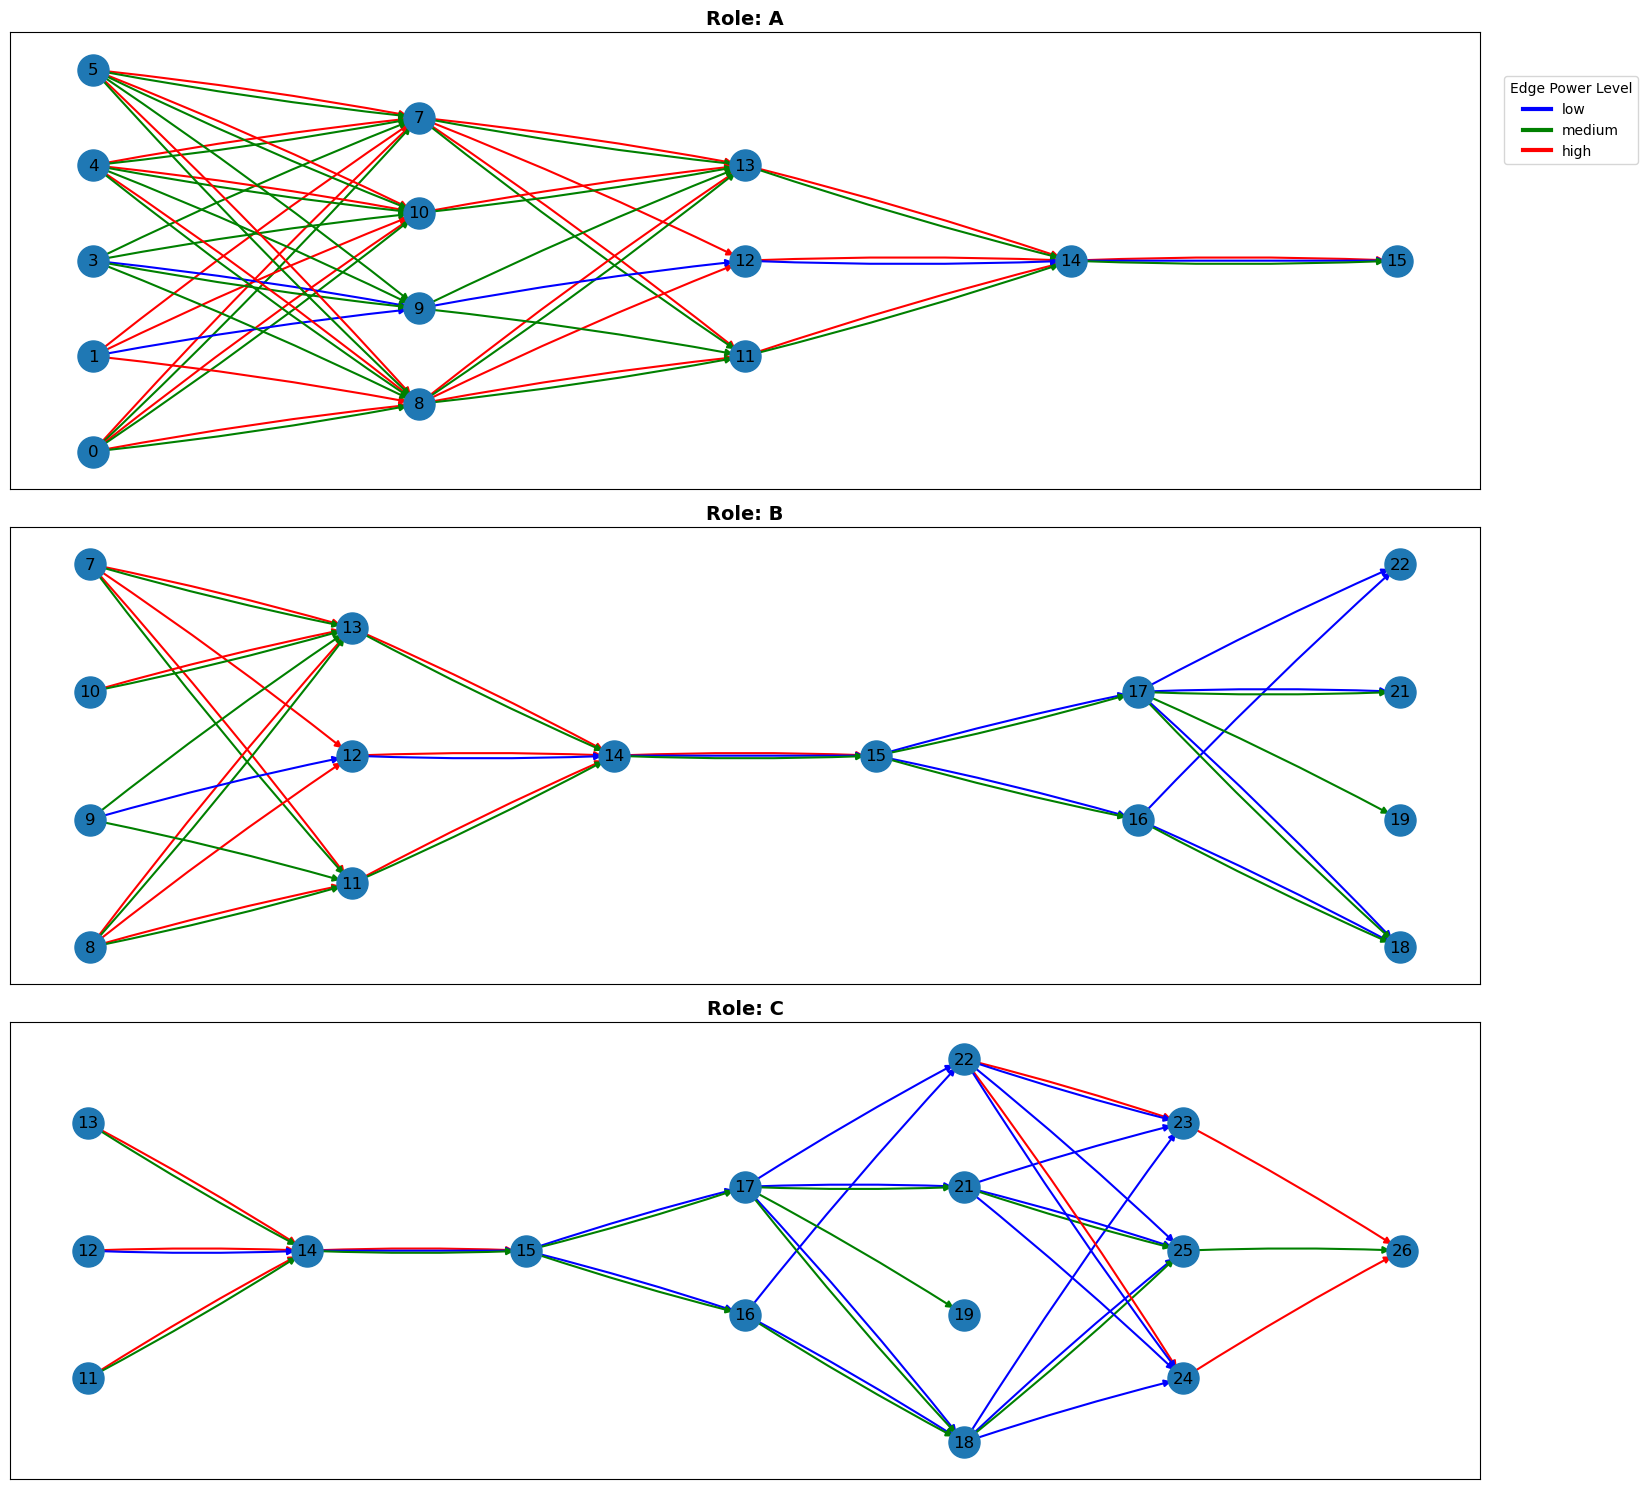

In [5]:
def sur_graph(G: nx.DiGraph) -> nx.DiGraph:
    h_nodes = []
    h_edges = []
    for n, d in G.nodes(data=True):
        if d['probability2'] > np.random.random():
            h_nodes.append(n)
    for u, v, d in G.edges(data=True):
        if u not in h_nodes or v not in h_nodes:
            continue
        if d['probability'] > np.random.random():
            h_edges.append((u,v))
    return G.edge_subgraph(h_edges)

# Success check
def success_eval(H: nx.DiGraph, sources: list, sink:int) -> bool:
    success = False
    for s in sources:
        if s not in H or sink not in H:
            continue
        if nx.has_path(H, s, sink):
            success = True
            break
    return success


H = sur_graph(G)
draw_role_graphs(H)

In [12]:
from collections import defaultdict
from tqdm import trange

N = 1000
sink = 26
passthrough_count = 0
path_counts = []
layer_0_nodes = [n for n,d in G.nodes(data=True) if d['layer'] == 0]
reachable_count = {s: defaultdict(int) for s in layer_0_nodes}
reach_mat = np.zeros((len(layer_0_nodes), (len(G.nodes())-len(layer_0_nodes))))
capacity_count = {s: 0 for s in layer_0_nodes}
criticality = defaultdict(int)


for _ in trange(N):

    H = sur_graph(G)
    source_nodes = [n for n,d in H.nodes(data=True) if d['layer'] == 0]
    success = success_eval(H, source_nodes, sink)
    passthrough_count += success
    if sink in H:
        path_counts.append(sum(1 for s in source_nodes for _ in nx.all_simple_paths(H, s, sink)))
    # Reachability & flow measurement 
    for i, s in enumerate(layer_0_nodes):
        if s not in H:
            #capacity_count[s].append(0)
            continue
        reach_mat[i, s-len(layer_0_nodes)] += 1
        reachable = nx.descendants(H, s)
        for v in reachable:
            reachable_count[s][v-len(layer_0_nodes)] += 1 
            reach_mat[i, v-len(layer_0_nodes)] += 1
        if sink not in H:
            #capacity_count[s].append(0)
            continue
        flow_value,_ = nx.maximum_flow(H, s, sink, capacity='capacity')
        capacity_count[s] += flow_value
    # Criticality
    if not success:
        for u,v,d in G.edges(data=True):
            if (u,v) not in H.edges():
                criticality[(u,v)] += 1

    
print(f'P(success): {passthrough_count/N}')
reachability_prob = {s: {v: cnt / N for v, cnt in reachable_count[s].items()}for s in layer_0_nodes}
print(f'Reachability: \n{reachability_prob}')
print(f'Criticality: \n{dict(criticality)}')
print(f'Max flow: \n{capacity_count}')

  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [00:05<00:00, 186.26it/s]

P(success): 0.63
Reachability: 
{0: {1: 0.394, 2: 0.614, 5: 0.622, 6: 0.602, 8: 0.786, 9: 0.77, 10: 0.647, 11: 0.755, 12: 0.567, 14: 0.505, 15: 0.703, 16: 0.689, 18: 0.743, 19: 0.488, 20: 0.498, 0: 0.514, 3: 0.54, 4: 0.732, 7: 0.74, 13: 0.523, 17: 0.687}, 1: {1: 0.733, 2: 0.562, 3: 0.759, 5: 0.764, 6: 0.743, 8: 0.969, 9: 0.951, 10: 0.799, 11: 0.934, 12: 0.709, 14: 0.627, 15: 0.865, 16: 0.854, 18: 0.917, 19: 0.602, 20: 0.622, 0: 0.461, 7: 0.899, 13: 0.654, 17: 0.842, 4: 0.573}, 2: {1: 0.519, 2: 0.646, 5: 0.593, 6: 0.573, 8: 0.754, 9: 0.74, 10: 0.634, 11: 0.726, 12: 0.551, 14: 0.492, 15: 0.679, 16: 0.668, 18: 0.717, 19: 0.473, 20: 0.486, 0: 0.356, 3: 0.428, 4: 0.624, 7: 0.703, 13: 0.5, 17: 0.658}, 3: {1: 0.577, 2: 0.629, 5: 0.671, 6: 0.647, 8: 0.84, 9: 0.826, 10: 0.694, 11: 0.811, 12: 0.614, 14: 0.538, 15: 0.753, 16: 0.737, 18: 0.796, 19: 0.521, 20: 0.539, 0: 0.579, 3: 0.434, 4: 0.747, 7: 0.793, 13: 0.565, 17: 0.727}, 4: {1: 0.485, 3: 0.435, 5: 0.493, 6: 0.483, 8: 0.621, 9: 0.61, 10: 0.5

In [13]:
reach_mat

array([[ 514.,  394.,  614.,  540.,  732.,  622.,  602.,  740.,  786.,
         770.,  647.,  755.,  567.,  523.,  505., 1505.,  689.,  687.,
         743.,  488.,  498.],
       [ 461.,  733.,  562.,  759.,  573.,  764.,  743.,  899.,  969.,
         951.,  799.,  934.,  709.,  654.,  627.,  865., 1844.,  842.,
         917.,  602.,  622.],
       [ 356.,  519.,  646.,  428.,  624.,  593.,  573.,  703.,  754.,
         740.,  634.,  726.,  551.,  500.,  492.,  679.,  668., 1429.,
         717.,  473.,  486.],
       [ 579.,  577.,  629.,  434.,  747.,  671.,  647.,  793.,  840.,
         826.,  694.,  811.,  614.,  565.,  538.,  753.,  737.,  727.,
        1655.,  521.,  539.],
       [ 287.,  485.,  456.,  435.,  551.,  493.,  483.,  589.,  621.,
         610.,  516.,  602.,  461.,  423.,  406.,  561.,  543.,  534.,
         589., 1023.,  400.],
       [ 433.,  680.,  520.,  597.,  708.,  749.,  720.,  886.,  948.,
         931.,  786.,  915.,  692.,  638.,  618.,  847.,  836.,  824.

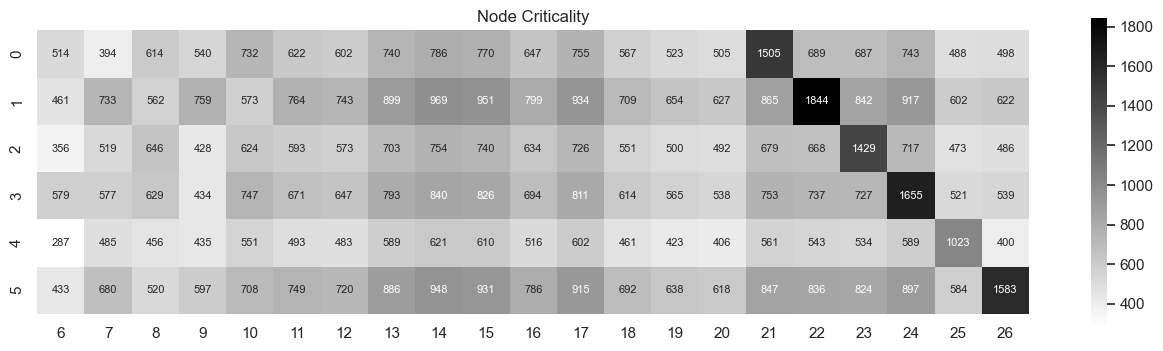

In [47]:
def shift_ticks(ax, shift:int):
    ticks = ax.get_xticks()
    labels = [int(float(lbl.get_text())) for lbl in ax.get_xticklabels()]
    ax.set_xticks(ticks)
    ax.set_xticklabels([l + shift for l in labels])

import seaborn as sns
plt.figure(figsize=(16, 4))
plt.rcParams['font.size'] = 8
ax = sns.heatmap(reach_mat, square=True, fmt='.0f', annot=True, cmap='gray_r')
shift_ticks(ax, 6)
plt.title('Node Criticality')
plt.show()